
# Social Network Analysis Using Centrality Metrics

## 1. Introduction

This project analyses the Karate Club social network using four centrality measures: Degree, Closeness, Betweenness, and Eigenvector Centrality.

## 2. Objectives

- Understand the structure of a social network.
- Calculate and rank nodes using four centrality metrics.
- Compare centrality scores and identify important nodes.
- Visualize the network and interpret the results.

## 3. Tools and Libraries

Python, Jupyter Notebook, NetworkX, Pandas, Matplotlib, and Seaborn.

## 4. Methodology

Load the dataset, calculate centrality scores, compare node rankings, visualize the network, and interpret the findings.


In [ ]:
%pip install networkx pandas matplotlib seaborn

In [4]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")
print("NetworkX version:", nx.__version__)
print("Pandas version:", pd.__version__)

All libraries imported successfully!
NetworkX version: 3.5
Pandas version: 2.3.3


In [1]:
import os

print("Current project folder:")
print(os.getcwd())

print("\nFiles and folders:")
print(os.listdir())

Current project folder:
C:\Users\Kishore\Documents\Social_Network_Analysis

Files and folders:
['.ipynb_checkpoints', 'data', 'main.ipynb', 'results']


In [9]:
%%writefile centrality_analysis.py

import networkx as nx
import pandas as pd


def calculate_centrality(G):
    """
    Calculate four centrality measures for every node
    in the given social network.
    """

    degree = nx.degree_centrality(G)
    closeness = nx.closeness_centrality(G)

    betweenness = nx.betweenness_centrality(
        G,
        normalized=True
    )

    eigenvector = nx.eigenvector_centrality(
        G,
        max_iter=1000
    )

    results = pd.DataFrame({
        "Node": list(G.nodes()),
        "Degree Centrality": [
            degree[n] for n in G.nodes()
        ],
        "Closeness Centrality": [
            closeness[n] for n in G.nodes()
        ],
        "Betweenness Centrality": [
            betweenness[n] for n in G.nodes()
        ],
        "Eigenvector Centrality": [
            eigenvector[n] for n in G.nodes()
        ]
    })

    return results


def rank_nodes(results, metric, top_n=5):
    """
    Return the highest-ranked nodes for a given metric.
    """

    if metric not in results.columns:
        raise ValueError(
            f"Unknown metric: {metric}"
        )

    return (
        results[["Node", metric]]
        .sort_values(
            by=metric,
            ascending=False
        )
        .head(top_n)
        .reset_index(drop=True)
    )


def calculate_metric_correlations(results):
    """
    Calculate correlations between centrality measures.
    """

    metrics = [
        "Degree Centrality",
        "Closeness Centrality",
        "Betweenness Centrality",
        "Eigenvector Centrality"
    ]

    return results[metrics].corr()

Overwriting centrality_analysis.py


In [10]:
import networkx as nx

from centrality_analysis import (
    calculate_centrality,
    rank_nodes,
    calculate_metric_correlations
)

# Load the Karate Club dataset
G = nx.karate_club_graph()

# Calculate all four centrality measures
results = calculate_centrality(G)

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

print("\nFirst five rows of centrality results:")
display(results.head())

print("\nTop five nodes by degree centrality:")
display(rank_nodes(results, "Degree Centrality", 5))

print("\nCorrelation between centrality metrics:")
display(calculate_metric_correlations(results).round(3))

Number of nodes: 34
Number of edges: 78

First five rows of centrality results:


,Node,Degree Centrality,Closeness Centrality,Betweenness Centrality,Eigenvector Centrality
0,0,0.484848,0.568966,0.437635,0.355483
1,1,0.272727,0.485294,0.053937,0.265954
2,2,0.303030,0.559322,0.143657,0.317189
3,3,0.181818,0.464789,0.011909,0.211174
4,4,0.090909,0.379310,0.000631,0.075966



Top five nodes by degree centrality:


,Node,Degree Centrality
0,33,0.515152
1,0,0.484848
2,32,0.363636
3,2,0.303030
4,1,0.272727



Correlation between centrality metrics:


,Degree Centrality,Closeness Centrality,Betweenness Centrality,Eigenvector Centrality
Degree Centrality,1.000,0.772,0.915,0.917
Closeness Centrality,0.772,1.000,0.718,0.905
Betweenness Centrality,0.915,0.718,1.000,0.803
Eigenvector Centrality,0.917,0.905,0.803,1.000


In [7]:

%%writefile visualization.py

import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns


def plot_network(G, scores=None, title="Social Network"):
    """
    Draw a social network.
    If scores are provided, node colors represent centrality.
    """

    pos = nx.spring_layout(G, seed=42)

    plt.figure(figsize=(10, 7))

    if scores is None:
        node_colors = "skyblue"
        color_map = None
    else:
        node_colors = [scores[n] for n in G.nodes()]
        color_map = plt.cm.viridis

    nx.draw_networkx(
        G,
        pos=pos,
        node_color=node_colors,
        cmap=color_map,
        node_size=600,
        edge_color="gray",
        font_size=9,
        with_labels=True
    )

    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()


def plot_top_nodes(results, metric, top_n=10):
    """
    Display a bar chart of the top-ranked nodes
    for the selected centrality metric.
    """

    top_nodes = results.nlargest(top_n, metric)

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=top_nodes,
        x="Node",
        y=metric
    )

    plt.title(f"Top {top_n} Nodes by {metric}")
    plt.xlabel("Node ID")
    plt.ylabel(metric)
    plt.tight_layout()
    plt.show()


def plot_metric_distributions(results):
    """
    Compare the score distributions of all four metrics.
    """

    metrics = [
        "Degree Centrality",
        "Closeness Centrality",
        "Betweenness Centrality",
        "Eigenvector Centrality"
    ]

    long_data = results.melt(
        id_vars="Node",
        value_vars=metrics,
        var_name="Centrality Metric",
        value_name="Score"
    )

    plt.figure(figsize=(12, 6))

    sns.boxplot(
        data=long_data,
        x="Centrality Metric",
        y="Score"
    )

    plt.title("Distribution of Centrality Metrics")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()


Overwriting visualization.py


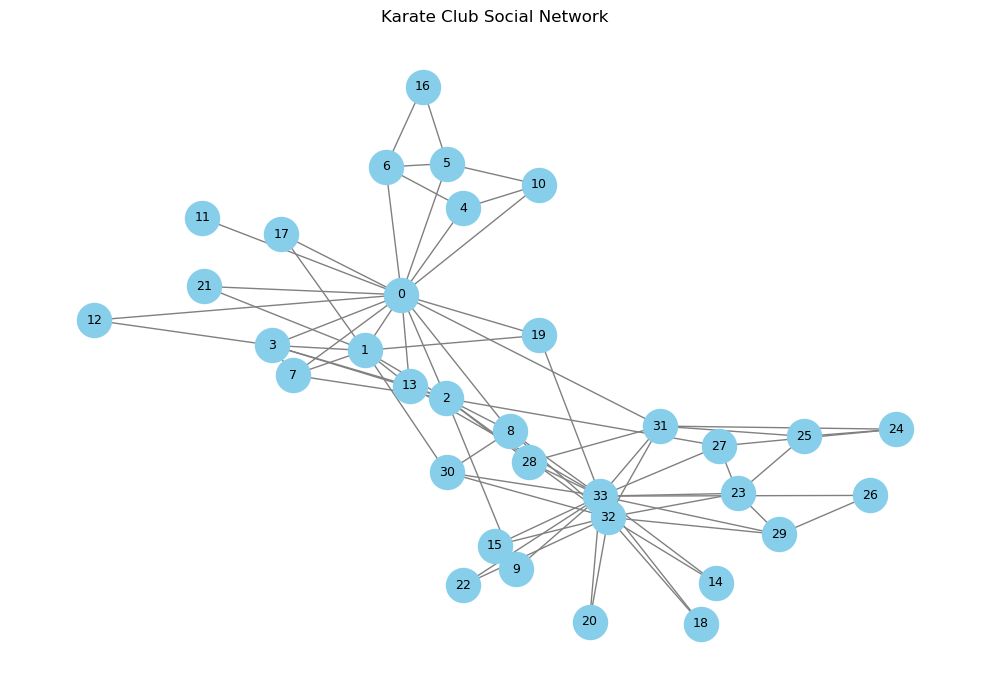

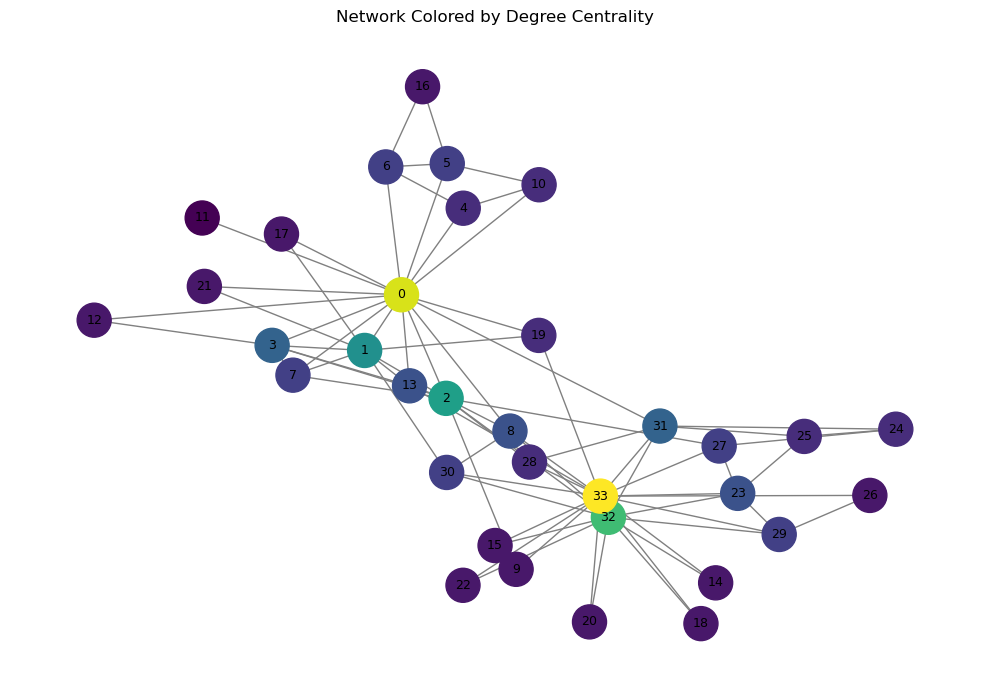

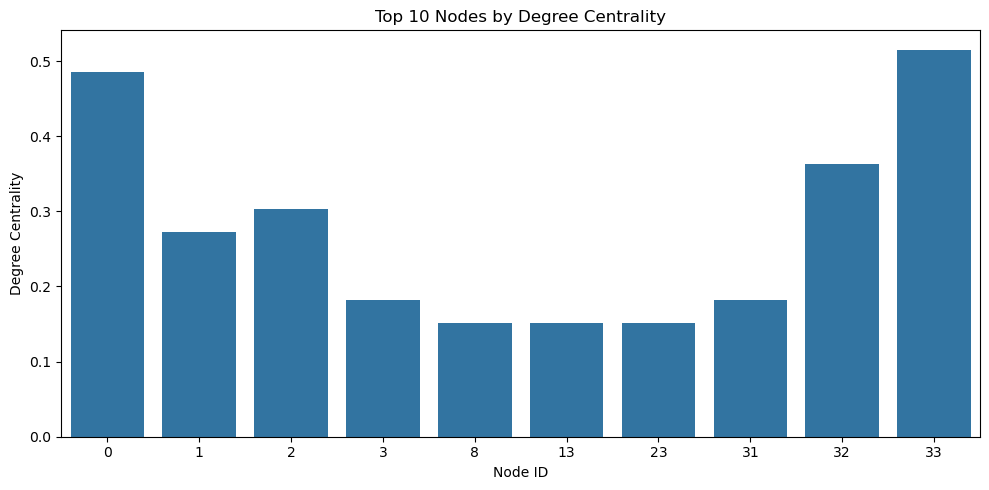

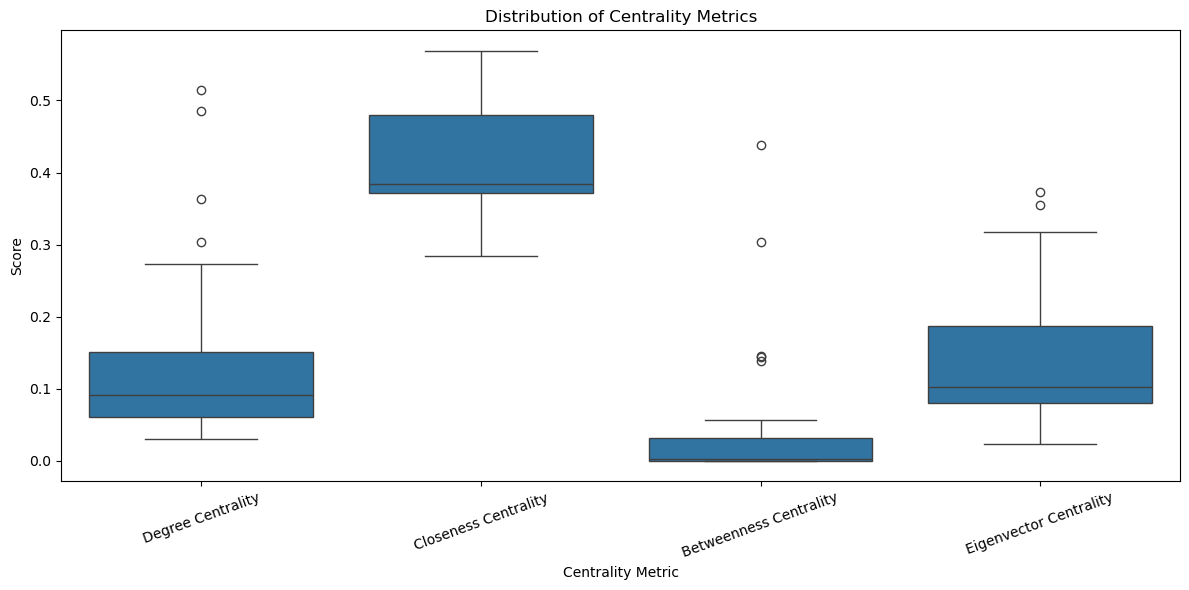

In [8]:

from visualization import (
    plot_network,
    plot_top_nodes,
    plot_metric_distributions
)

# Draw the original network
plot_network(
    G,
    title="Karate Club Social Network"
)

# Highlight nodes according to degree centrality
plot_network(
    G,
    scores=nx.degree_centrality(G),
    title="Network Colored by Degree Centrality"
)

# Show the highest-ranked nodes
plot_top_nodes(
    results,
    "Degree Centrality",
    top_n=10
)

# Compare the distributions of all four metrics
plot_metric_distributions(results)


In [12]:

import os
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

from centrality_analysis import (
    calculate_centrality,
    rank_nodes,
    calculate_metric_correlations
)

from visualization import (
    plot_network,
    plot_top_nodes,
    plot_metric_distributions
)

# Load the Karate Club dataset
G = nx.karate_club_graph()

# Calculate centrality scores
results = calculate_centrality(G)

print("Dataset loaded successfully.")
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Network type:", "Directed" if G.is_directed() else "Undirected")

display(results.head())


Dataset loaded successfully.
Number of nodes: 34
Number of edges: 78
Network type: Undirected


,Node,Degree Centrality,Closeness Centrality,Betweenness Centrality,Eigenvector Centrality
0,0,0.484848,0.568966,0.437635,0.355483
1,1,0.272727,0.485294,0.053937,0.265954
2,2,0.303030,0.559322,0.143657,0.317189
3,3,0.181818,0.464789,0.011909,0.211174
4,4,0.090909,0.379310,0.000631,0.075966


In [14]:

metrics = [
    "Degree Centrality",
    "Closeness Centrality",
    "Betweenness Centrality",
    "Eigenvector Centrality"
]

for metric in metrics:
    print(f"\nTop 10 Nodes by {metric}")
    display(rank_nodes(results, metric, top_n=10))



Top 10 Nodes by Degree Centrality


,Node,Degree Centrality
0,33,0.515152
1,0,0.484848
2,32,0.363636
3,2,0.303030
4,1,0.272727
5,3,0.181818
6,31,0.181818
7,23,0.151515
8,8,0.151515
9,13,0.151515



Top 10 Nodes by Closeness Centrality


,Node,Closeness Centrality
0,0,0.568966
1,2,0.559322
2,33,0.550000
3,31,0.540984
4,13,0.515625
5,32,0.515625
6,8,0.515625
7,19,0.500000
8,1,0.485294
9,3,0.464789



Top 10 Nodes by Betweenness Centrality


,Node,Betweenness Centrality
0,0,0.437635
1,33,0.304075
2,32,0.145247
3,2,0.143657
4,31,0.138276
5,8,0.055927
6,1,0.053937
7,13,0.045863
8,19,0.032475
9,5,0.029987



Top 10 Nodes by Eigenvector Centrality


,Node,Eigenvector Centrality
0,33,0.373371
1,0,0.355483
2,2,0.317189
3,32,0.308651
4,1,0.265954
5,8,0.227405
6,13,0.226470
7,3,0.211174
8,31,0.191036
9,30,0.174760


Correlation Matrix


,Degree Centrality,Closeness Centrality,Betweenness Centrality,Eigenvector Centrality
Degree Centrality,1.000,0.772,0.915,0.917
Closeness Centrality,0.772,1.000,0.718,0.905
Betweenness Centrality,0.915,0.718,1.000,0.803
Eigenvector Centrality,0.917,0.905,0.803,1.000


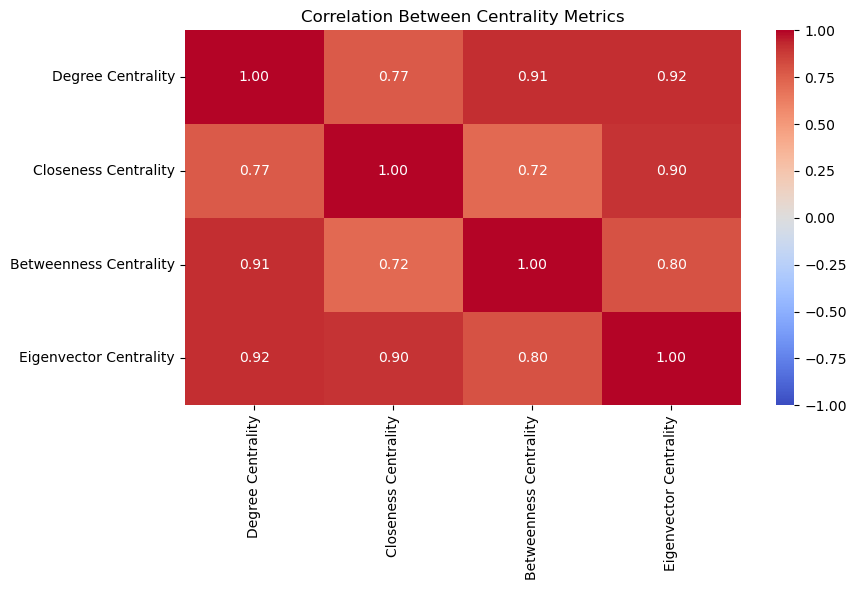

In [16]:

correlation_matrix = calculate_metric_correlations(results)

print("Correlation Matrix")
display(correlation_matrix.round(3))

plt.figure(figsize=(9, 6))

import seaborn as sns

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Between Centrality Metrics")
plt.tight_layout()
plt.show()


In [18]:

# Create a ranking for each metric.
rankings = results[["Node"]].copy()

for metric in metrics:
    rankings[metric + " Rank"] = (
        results[metric]
        .rank(ascending=False, method="min")
        .astype(int)
    )

rank_columns = [metric + " Rank" for metric in metrics]

# Average rank across all four metrics.
rankings["Average Rank"] = (
    rankings[rank_columns].mean(axis=1)
)

rankings = rankings.sort_values("Average Rank")

print("Nodes with the best average rank across all four metrics:")
display(rankings.head(10).round(2))


Nodes with the best average rank across all four metrics:


,Node,Degree Centrality Rank,Closeness Centrality Rank,Betweenness Centrality Rank,Eigenvector Centrality Rank,Average Rank
0,0,2,1,1,2,1.50
33,33,1,3,2,1,1.75
2,2,4,2,4,3,3.25
32,32,3,5,3,4,3.75
31,31,6,4,5,9,6.00
8,8,8,5,6,6,6.25
1,1,5,9,7,5,6.50
13,13,8,5,8,7,7.00
3,3,6,10,15,8,9.75
30,30,11,11,14,10,11.50


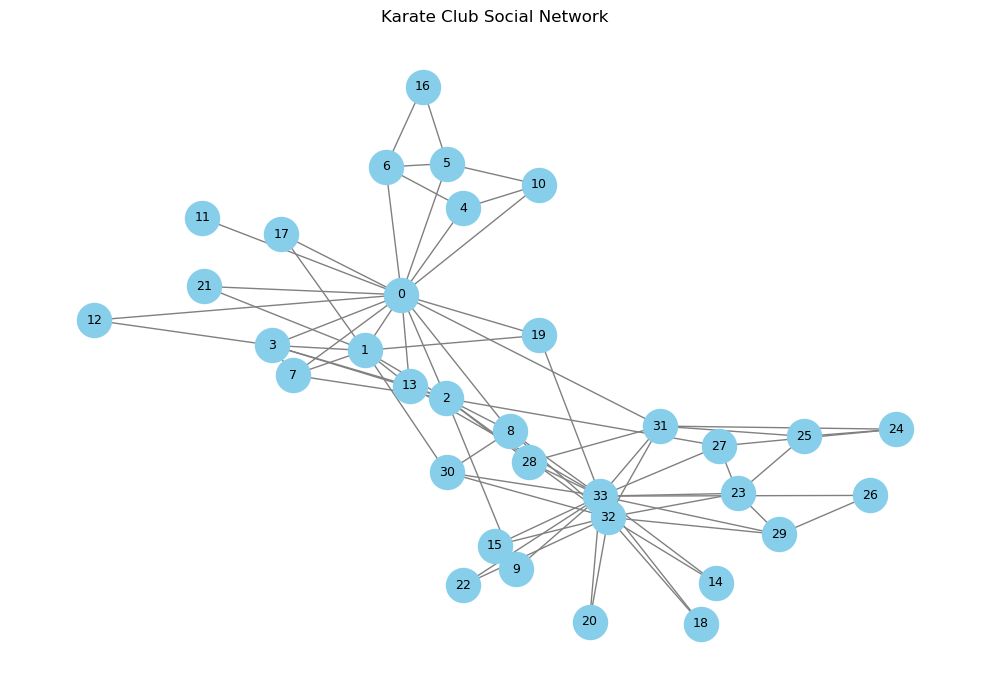

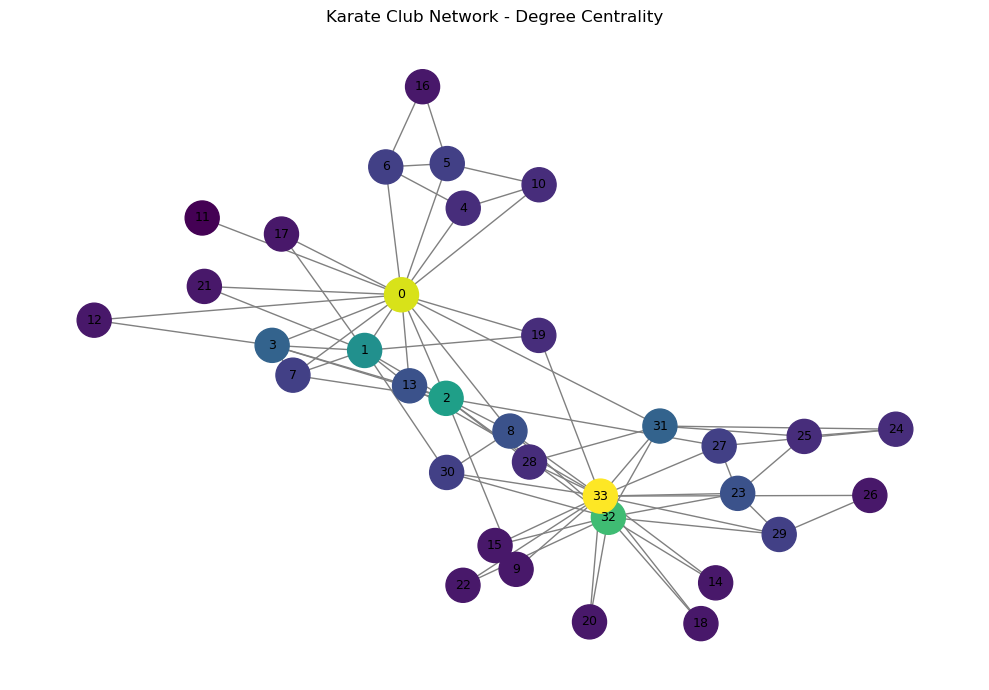

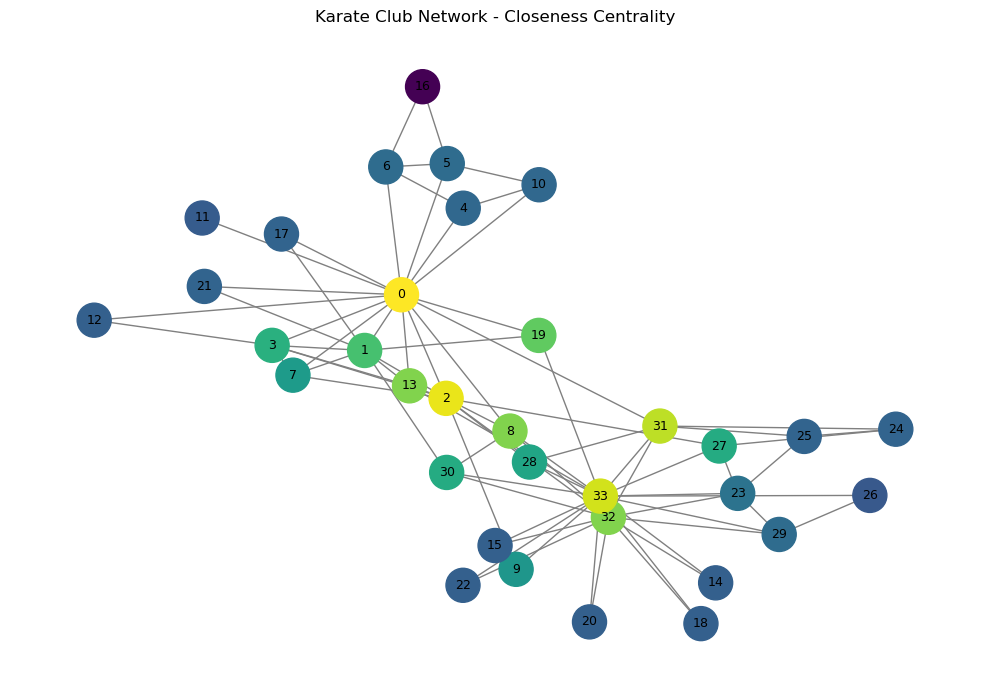

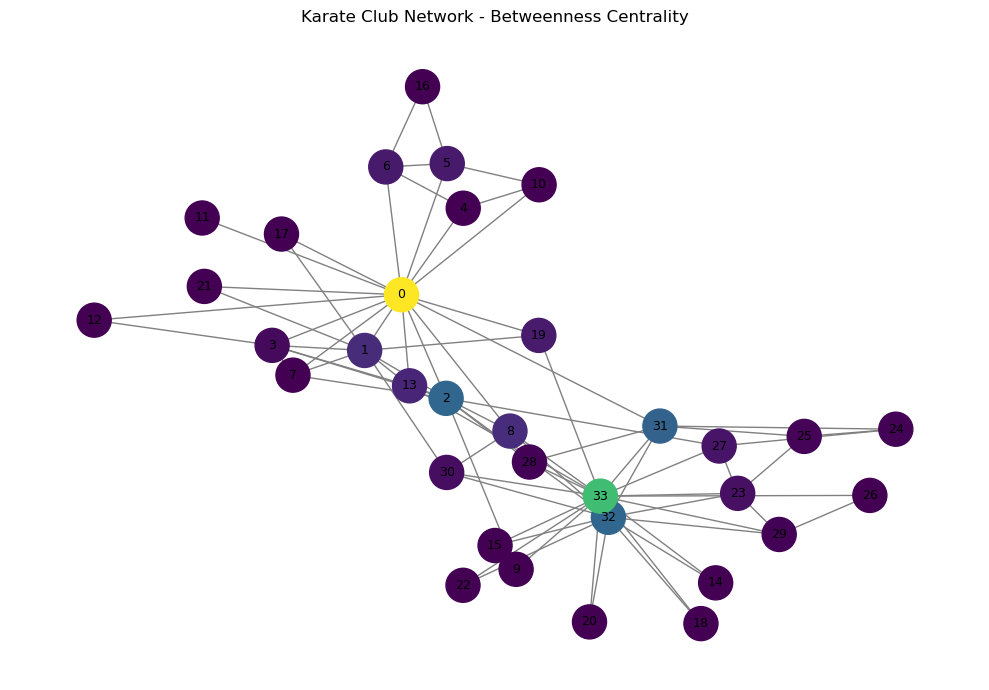

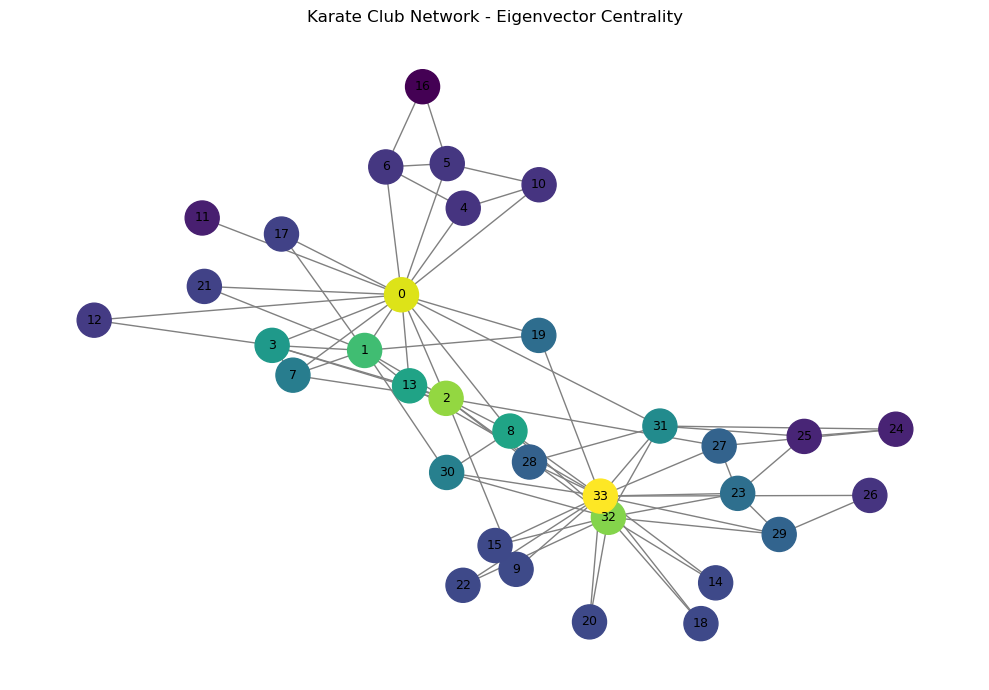

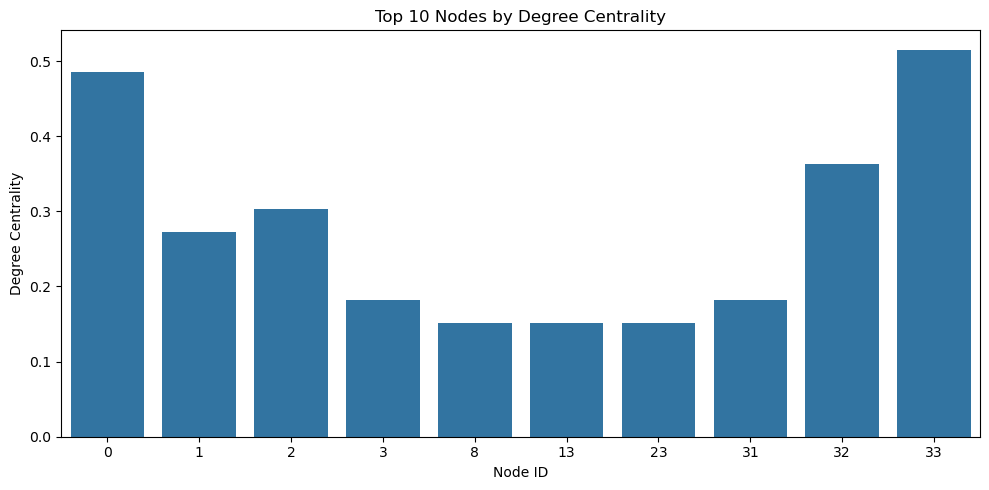

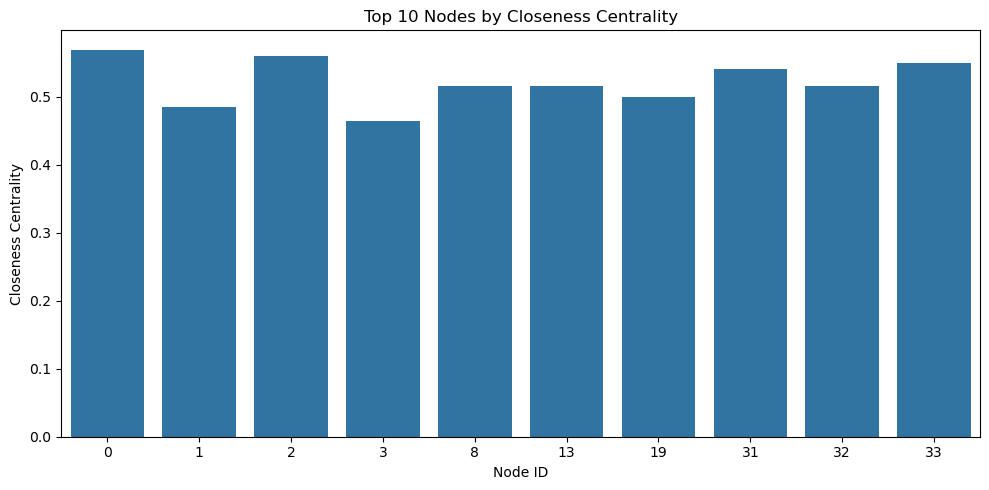

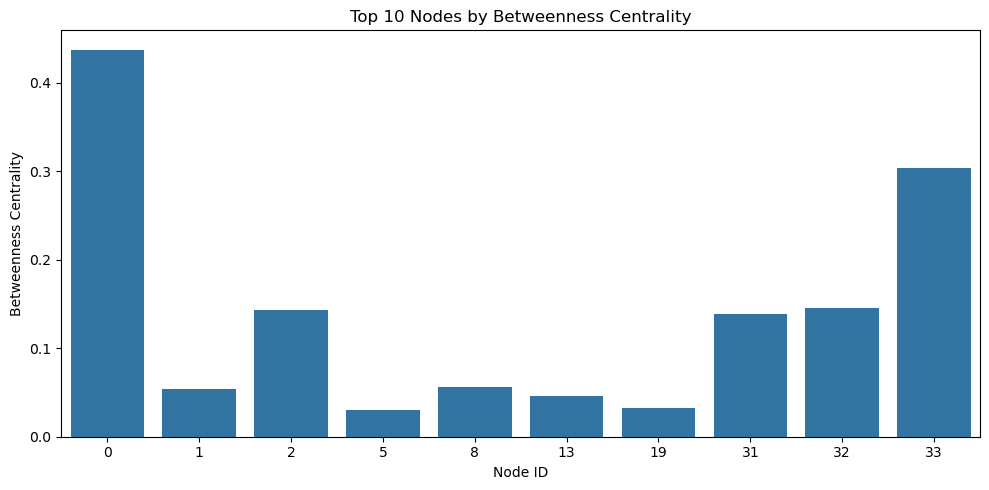

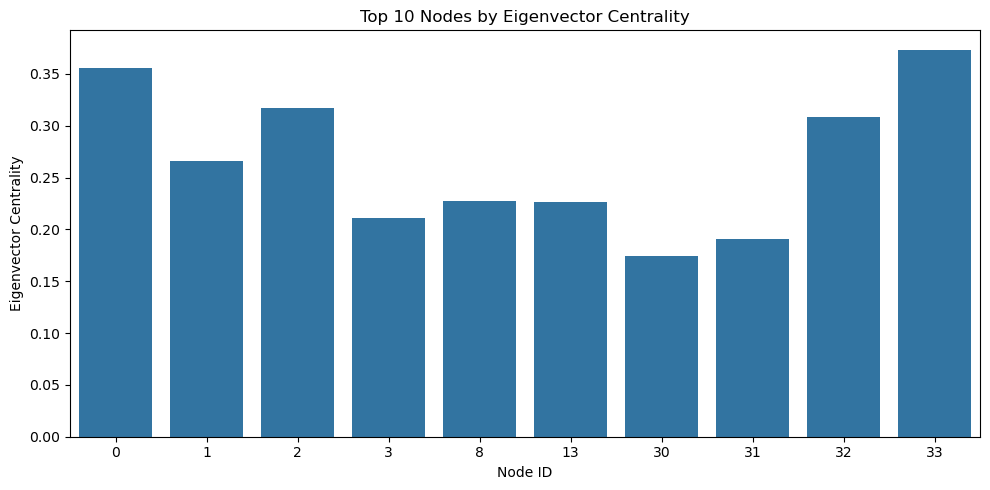

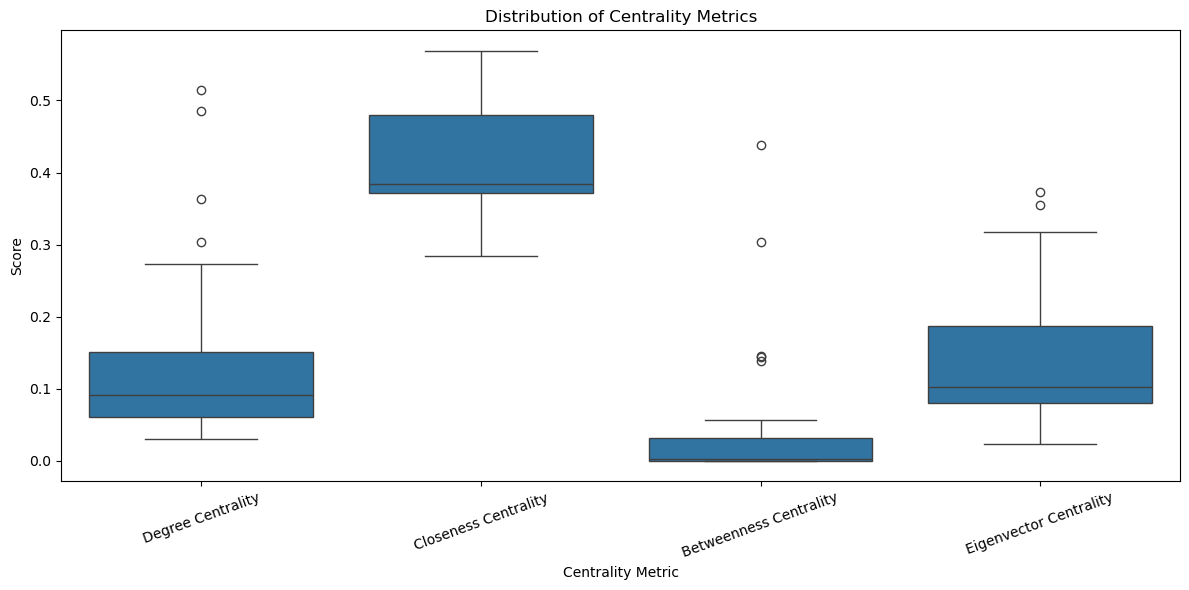

In [20]:

# Original network
plot_network(
    G,
    title="Karate Club Social Network"
)

# Visualize each centrality measure
centrality_scores = {
    "Degree Centrality": nx.degree_centrality(G),
    "Closeness Centrality": nx.closeness_centrality(G),
    "Betweenness Centrality": nx.betweenness_centrality(G),
    "Eigenvector Centrality": nx.eigenvector_centrality(
        G, max_iter=1000
    )
}

for metric, scores in centrality_scores.items():
    plot_network(
        G,
        scores=scores,
        title=f"Karate Club Network - {metric}"
    )

# Compare the highest-scoring nodes
for metric in metrics:
    plot_top_nodes(results, metric, top_n=10)

# Compare score distributions
plot_metric_distributions(results)


In [22]:
from pathlib import Path

# Create the results folder if it doesn't exist
output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

# Save the centrality results
results.to_csv(
    output_dir / "centrality_results.csv",
    index=False
)

# Save the correlation matrix
correlation_matrix.to_csv(
    output_dir / "centrality_correlations.csv"
)

# Save the combined rankings
rankings.to_csv(
    output_dir / "combined_node_rankings.csv",
    index=False
)

print("Files saved successfully!")
print("Location:", output_dir.resolve())

Files saved successfully!
Location: C:\Users\Kishore\Documents\Social_Network_Analysis\results


In [37]:
from pathlib import Path

for file in Path("results").iterdir():
    print(file)

results\betweenness_centrality_top10.png
results\centrality_correlations.csv
results\centrality_correlation_heatmap.png
results\centrality_distributions.png
results\centrality_results.csv
results\closeness_centrality_top10.png
results\combined_node_rankings.csv
results\degree_centrality_top10.png
results\eigenvector_centrality_top10.png
results\social_network.png


In [39]:
from pathlib import Path

print("Files saved in results:")
for file in sorted(Path("results").iterdir()):
    print(file.name)

Files saved in results:
betweenness_centrality_top10.png
centrality_correlation_heatmap.png
centrality_correlations.csv
centrality_distributions.png
centrality_results.csv
closeness_centrality_top10.png
combined_node_rankings.csv
degree_centrality_top10.png
eigenvector_centrality_top10.png
social_network.png


In [41]:
from pathlib import Path

readme_content = """# Social Network Analysis Using Centrality Metrics

## 1. Project Overview
This project analyses a social network using graph theory and Social Network Analysis (SNA) techniques. It identifies important nodes based on their connections, influence, and positions within the network.

## 2. Objectives
- Analyse the structure of a social network.
- Calculate Degree, Closeness, Betweenness, and Eigenvector Centrality.
- Identify the top-ranked nodes for each centrality metric.
- Study correlations between centrality metrics.
- Visualise the network and centrality results.

## 3. Dataset
The project uses the built-in Karate Club social network dataset provided by NetworkX.

- Nodes: 34
- Edges: 78
- Network type: Undirected graph

## 4. Technologies Used
- Python
- Jupyter Notebook
- NetworkX
- Pandas
- Matplotlib
- Seaborn

## 5. Centrality Metrics
- **Degree Centrality:** Measures the number of direct connections relative to the maximum possible connections.
- **Closeness Centrality:** Measures how close a node is to other nodes based on shortest paths.
- **Betweenness Centrality:** Measures how frequently a node lies on shortest paths between other nodes.
- **Eigenvector Centrality:** Measures a node's importance based on its connections to other important nodes.

## 6. Project Structure
- main.ipynb: Main analysis and results.
- centrality_analysis.py: Centrality calculations, rankings, and correlations.
- visualization.py: Network and chart visualisation functions.
- data/: Dataset folder.
- results/: Exported CSV files and visualisations.
- requirements.txt: Required Python libraries.

## 7. How to Run
1. Install Python and Jupyter Notebook.
2. Install the required libraries using `pip install -r requirements.txt`.
3. Open main.ipynb in Jupyter Notebook.
4. Run the notebook cells in order.

## 8. Outputs
The results folder contains:
- Centrality scores for all nodes.
- Correlation matrix for the four centrality metrics.
- Combined node rankings.
- Social network graph.
- Centrality bar charts.
- Centrality correlation heatmap.
- Centrality distribution chart.

## 9. Conclusion
This project demonstrates how centrality metrics can be used to identify structurally important nodes in a social network. Comparing multiple metrics provides different perspectives on connectivity, information flow, and node influence.
"""

Path("README.md").write_text(readme_content, encoding="utf-8")

print("README.md created at:", Path("README.md").resolve())

README.md created at: C:\Users\Kishore\Documents\Social_Network_Analysis\README.md


In [43]:
from pathlib import Path

requirements = """networkx
pandas
matplotlib
seaborn
jupyter
"""

Path("requirements.txt").write_text(requirements, encoding="utf-8")

print("requirements.txt created at:", Path("requirements.txt").resolve())

requirements.txt created at: C:\Users\Kishore\Documents\Social_Network_Analysis\requirements.txt


In [45]:
from pathlib import Path

print("Main project folder:")
for item in sorted(Path(".").iterdir()):
    print(item.name)

print("\nResults folder:")
for item in sorted(Path("results").iterdir()):
    print(item.name)

Main project folder:
.ipynb_checkpoints
__pycache__
centrality_analysis.py
data
main.ipynb
README.md
requirements.txt
results
visualization.py

Results folder:
betweenness_centrality_top10.png
centrality_correlation_heatmap.png
centrality_correlations.csv
centrality_distributions.png
centrality_results.csv
closeness_centrality_top10.png
combined_node_rankings.csv
degree_centrality_top10.png
eigenvector_centrality_top10.png
social_network.png
